#### **Exploratory Data Analysis & Spare-Parts Demand Classification**

**Objective:**
1. Execute the preprocessing pipeline to construct a balanced 36-month part-level demand panel (explicitly capturing zero-demand months).
2. Analyze top-consuming parts, vehicle-type demand drivers, and seasonal consumption patterns.
3. Segment all 24 spare parts using Syntetos-Boylan Demand Classification (ADI vs. CV^2) into Fast-Moving, Slow-Moving, Intermittent, and Lumpy profiles.
4. Evaluate maintenance KPIs: Preventive Maintenance (PM) Demand Share, Demand Growth Rate, and Repeat-Failure Rate.

#### **Imports & Pipeline Execution**

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from src.preprocessing import load_raw_data, run_preprocessing_pipeline

# Load raw tables & run preprocessing pipeline
raw_data = load_raw_data(raw_dir="../data/raw")
processed = run_preprocessing_pipeline(
    raw_dir="../data/raw",
    processed_dir="../data/processed"
)

monthly_part_df = processed["monthly_part_panel"]
monthly_veh_df = processed["monthly_vehicle_panel"]
part_summary_df = processed["part_classification"]

print(f"Monthly Part Panel Shape: {monthly_part_df.shape} (24 parts x 36 months)")
print(f"Total 36-Month Units Issued: {part_summary_df['total_demand_36m'].sum():,}")
print(f"Total 36-Month Spend (AED): {part_summary_df['total_spend_aed'].sum():,.2f}")

Monthly Part Panel Shape: (864, 14) (24 parts x 36 months)
Total 36-Month Units Issued: 16,779
Total 36-Month Spend (AED): 5,166,380.00


#### **Check Missing Values & Zero-Demand Months**

##### 1. Data Integrity & Balanced Panel Verification
- Confirm that every part has a complete 36-month time series (`2023-01-01` to `2025-12-01`) with zero missing values and explicit `0` entries for non-demand months.

In [2]:
months_per_part = monthly_part_df.groupby("part_number")["month"].count().unique()
zero_month_rows = (monthly_part_df["demand_qty"] == 0).sum()

print(f"Months per part: {months_per_part[0]} months")
print(f"Date range: {monthly_part_df['month'].min().date()} to {monthly_part_df['month'].max().date()}")
print(f"Null count across panel: {monthly_part_df.isnull().sum().sum()}")
print(f"Explicit zero-demand part-months preserved: {zero_month_rows} out of {len(monthly_part_df)} ({zero_month_rows/len(monthly_part_df):.1%})")

Months per part: 36 months
Date range: 2023-01-01 to 2025-12-01
Null count across panel: 0
Explicit zero-demand part-months preserved: 228 out of 864 (26.4%)


#### **Top 10 Parts Summary & Chart**

,part_number,part_name,category,demand_pattern,total_demand_36m,avg_monthly_demand,total_spend_aed
0,PRT-004,Cabin & A/C Pollen Filter,HVAC & Cooling,Fast-Moving,2431,67.53,182325.0
1,PRT-003,Engine Air Intake Filter Element,Filters & Fluids,Fast-Moving,2431,67.53,352495.0
2,PRT-005,Front Disc Brake Pad Set,Braking System,Fast-Moving,2257,62.69,947940.0
3,PRT-001,Heavy-Duty Engine Oil Filter,Filters & Fluids,Fast-Moving,2040,56.67,132600.0
4,PRT-006,Rear Brake Shoe & Lining Kit,Braking System,Fast-Moving,2036,56.56,773680.0
5,PRT-002,Primary Fuel Water Separator Filter,Filters & Fluids,Fast-Moving,2012,55.89,221320.0
6,PRT-021,Heavy-Duty 150Ah AGM Fleet Battery,Electrical & Lighting,Intermittent,357,9.92,278460.0
7,PRT-011,Radiator Upper & Lower Hose Kit,HVAC & Cooling,Slow-Moving,331,9.19,69510.0
8,PRT-007,Heavy-Duty Wiper Blade Pair,Body & Exterior,Slow-Moving,317,8.81,17435.0
9,PRT-010,Serpentine Drive Belt,Engine & Drivetrain,Slow-Moving,303,8.42,40905.0


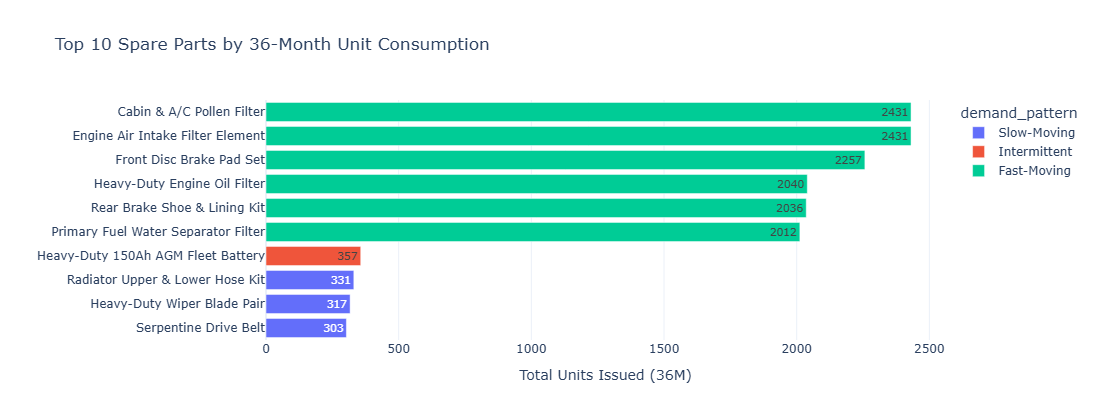

In [3]:
top10_vol = part_summary_df.nlargest(10, "total_demand_36m")[
    [
        "part_number",
        "part_name",
        "category",
        "demand_pattern",
        "total_demand_36m",
        "avg_monthly_demand",
        "total_spend_aed",
    ]
]
display(top10_vol)

fig_top10 = px.bar(
    top10_vol.sort_values("total_demand_36m"),
    x="total_demand_36m",
    y="part_name",
    color="demand_pattern",
    orientation="h",
    title="Top 10 Spare Parts by 36-Month Unit Consumption",
    labels={"total_demand_36m": "Total Units Issued (36M)", "part_name": ""},
    text_auto=True,
)
fig_top10.update_layout(height=420, template="plotly_white")
fig_top10.show()

#### **Vehicle Type & Category Breakdown**

##### 3. Demand by Vehicle Type & Part Category
- Determine which commercial vehicle classes consume the most spare parts and generate the highest maintenance spend.

,vehicle_type,total_units,total_spend_aed,total_work_orders,repeat_failures,demand_share_pct
1,Heavy-Duty Truck,5703,1755200.0,2770,77,33.99
2,Medium-Duty Box Truck,3948,1158160.0,1913,43,23.53
0,Delivery Van,3319,965205.0,1588,47,19.78
3,Refrigerated Chiller Truck,2225,826375.0,1011,34,13.26
4,Utility Pickup,1584,461440.0,775,11,9.44


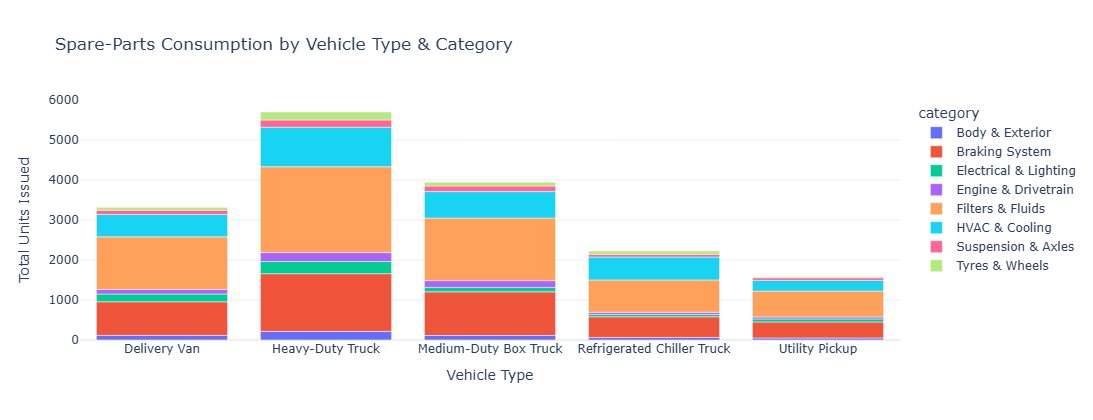

In [5]:
veh_summary = (
    monthly_veh_df.groupby("vehicle_type", as_index=False)
    .agg(
        total_units=("demand_qty", "sum"),
        total_spend_aed=("total_cost_aed", "sum"),
        total_work_orders=("work_order_count", "sum"),
        repeat_failures=("repeat_fail_events", "sum"),
    )
    .sort_values("total_units", ascending=False)
)
veh_summary["demand_share_pct"] = (
    veh_summary["total_units"] / veh_summary["total_units"].sum() * 100
).round(2)

display(veh_summary)

fig_veh = px.bar(
    monthly_veh_df.groupby(["vehicle_type", "category"], as_index=False)["demand_qty"].sum(),
    x="vehicle_type",
    y="demand_qty",
    color="category",
    title="Spare-Parts Consumption by Vehicle Type & Category",
    labels={"vehicle_type": "Vehicle Type", "demand_qty": "Total Units Issued"},
)
fig_veh.update_layout(height=420, template="plotly_white")
fig_veh.show()

#### **Monthly Trend & Seasonal Profile**

##### 4. Monthly & Seasonal Fleet Demand Trends
- Examine overall fleet consumption over time, checking for UAE summer heat surges (May–September) across cooling, electrical, and tyre components.

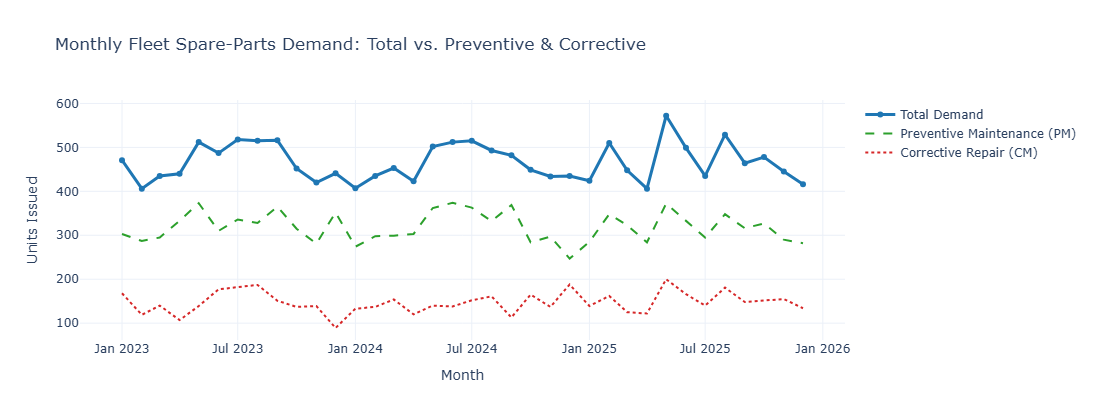

In [6]:
monthly_total = (
    monthly_part_df.groupby("month", as_index=False)
    .agg(
        total_demand=("demand_qty", "sum"),
        pm_demand=("pm_qty", "sum"),
        cm_demand=("cm_qty", "sum"),
        total_spend_aed=("total_cost_aed", "sum"),
    )
)

fig_trend = go.Figure()
fig_trend.add_trace(
    go.Scatter(
        x=monthly_total["month"],
        y=monthly_total["total_demand"],
        mode="lines+markers",
        name="Total Demand",
        line=dict(width=3, color="#1f77b4"),
    )
)
fig_trend.add_trace(
    go.Scatter(
        x=monthly_total["month"],
        y=monthly_total["pm_demand"],
        mode="lines",
        name="Preventive Maintenance (PM)",
        line=dict(dash="dash", color="#2ca02c"),
    )
)
fig_trend.add_trace(
    go.Scatter(
        x=monthly_total["month"],
        y=monthly_total["cm_demand"],
        mode="lines",
        name="Corrective Repair (CM)",
        line=dict(dash="dot", color="#d62728"),
    )
)
fig_trend.update_layout(
    title="Monthly Fleet Spare-Parts Demand: Total vs. Preventive & Corrective",
    xaxis_title="Month",
    yaxis_title="Units Issued",
    height=420,
    template="plotly_white",
)
fig_trend.show()

#### **Demand Pattern Distribution & Scatter Matrix**

##### Demand Pattern Segmentation (ADI vs. CV^2)
Spare parts cannot all be forecasted with the same algorithm. Using Average Demand Interval (ADI) and Squared Coefficient of Variation (CV^2):
* **Fast-Moving:** Low intermittency (ADI < 1.32), smooth demand (CV^2 < 0.49), high monthly volume.
* **Slow-Moving:** Low intermittency (ADI < 1.32$), smooth demand (CV^2 < 0.49), low steady volume.
* **Intermittent:** Many zero-demand months (ADI \ge 1.32), consistent order size (CV^2 < 0.49).
* **Lumpy:** Many zero-demand months (ADI \ge 1.32), highly erratic order sizes (CV^2 \ge 0.49).

,demand_pattern,part_count,total_units,avg_intermittency_pct,total_spend_aed
0,Fast-Moving,6,13207,0.000000,2610360.0
1,Intermittent,12,1866,52.084167,2277910.0
2,Slow-Moving,6,1706,1.390000,278110.0


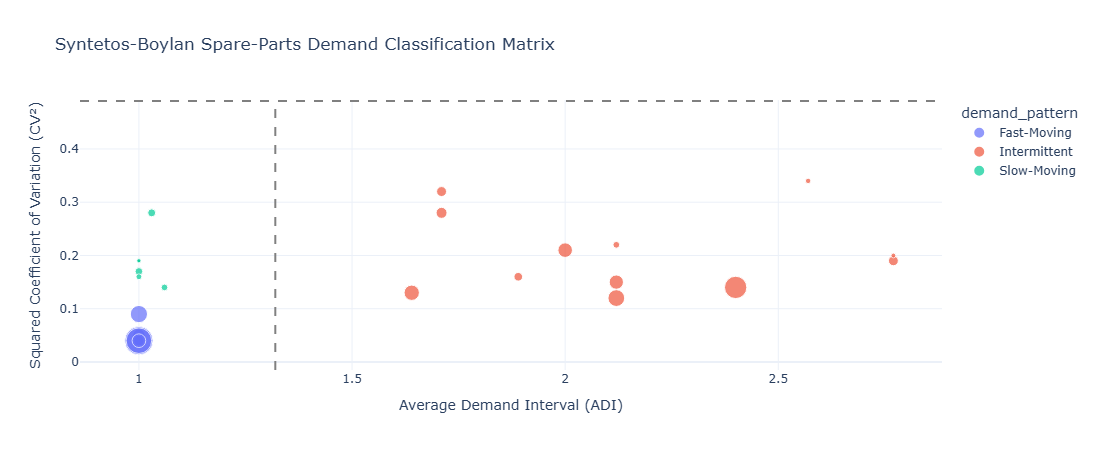

In [7]:
pattern_counts = (
    part_summary_df.groupby("demand_pattern", as_index=False)
    .agg(
        part_count=("part_number", "count"),
        total_units=("total_demand_36m", "sum"),
        avg_intermittency_pct=("intermittency_rate_pct", "mean"),
        total_spend_aed=("total_spend_aed", "sum"),
    )
)
display(pattern_counts)

fig_sb = px.scatter(
    part_summary_df,
    x="adi",
    y="cv2",
    color="demand_pattern",
    size="total_spend_aed",
    hover_name="part_name",
    hover_data=["part_number", "intermittency_rate_pct", "avg_monthly_demand"],
    title="Syntetos-Boylan Spare-Parts Demand Classification Matrix",
    labels={
        "adi": "Average Demand Interval (ADI)",
        "cv2": "Squared Coefficient of Variation (CV²)",
    },
)
# Add standard Syntetos-Boylan threshold lines
fig_sb.add_vline(x=1.32, line_dash="dash", line_color="gray")
fig_sb.add_hline(y=0.49, line_dash="dash", line_color="gray")
fig_sb.update_layout(height=450, template="plotly_white")
fig_sb.show()

#### **KPI Flagging Inspection Table**

##### Maintenance & Reliability Diagnostics
Inspect parts exceeding operational thresholds:
* **Demand Growth Rate > +10%** (recent 6 months vs. prior 6 months)
* **Intermittency Rate > 50%** (requires Croston's / specialized forecasting)
* **Elevated Repeat-Failure Rate** (indicates reliability or installation issues)

In [8]:
kpi_view = part_summary_df[
    [
        "part_number",
        "part_name",
        "demand_pattern",
        "intermittency_rate_pct",
        "demand_growth_pct",
        "pm_demand_share_pct",
        "repeat_failure_count",
        "repeat_failure_rate_pct",
    ]
].copy()

print("-- Parts with Demand Growth > 10% --")
display(kpi_view[kpi_view["demand_growth_pct"] > 10].sort_values("demand_growth_pct", ascending=False))

print("\n-- Parts with Highest Repeat-Failure Rates ---")
display(kpi_view.sort_values("repeat_failure_rate_pct", ascending=False).head(6))

print("\n-- Intermittent & Lumpy Parts (Intermittency > 50%) --")
display(kpi_view[kpi_view["intermittency_rate_pct"] > 50].sort_values("intermittency_rate_pct", ascending=False))

-- Parts with Demand Growth > 10% --


,part_number,part_name,demand_pattern,intermittency_rate_pct,demand_growth_pct,pm_demand_share_pct,repeat_failure_count,repeat_failure_rate_pct
19,PRT-013,12V/24V Heavy Commercial Alternator,Intermittent,47.22,700.00,19.67,0,0.00
10,PRT-023,Front Shock Absorber Strut Pair,Intermittent,52.78,75.00,50.00,1,3.23
13,PRT-008,Heated Side View Mirror Assembly,Slow-Moving,2.78,22.50,22.31,9,5.66
18,PRT-016,A/C Compressor Assembly,Intermittent,41.67,16.67,22.58,2,5.26
0,PRT-004,Cabin & A/C Pollen Filter,Fast-Moving,0.00,16.09,78.69,16,1.32
9,PRT-010,Serpentine Drive Belt,Slow-Moving,0.00,13.04,76.57,8,3.86



-- Parts with Highest Repeat-Failure Rates ---


,part_number,part_name,demand_pattern,intermittency_rate_pct,demand_growth_pct,pm_demand_share_pct,repeat_failure_count,repeat_failure_rate_pct
23,PRT-018,NOx Exhaust Gas Sensor,Intermittent,61.11,0.00,10.53,10,40.00
15,PRT-024,Refrigeration Unit Evaporator Fan Motor,Intermittent,50.00,-84.75,39.11,7,28.00
20,PRT-014,Electronic Turbocharger Actuator,Intermittent,63.89,-63.64,18.37,8,25.00
6,PRT-021,Heavy-Duty 150Ah AGM Fleet Battery,Intermittent,38.89,-40.00,34.45,4,10.26
12,PRT-019,315/80 R22.5 All-Position Radial Tyre,Intermittent,52.78,-22.86,60.47,2,8.00
13,PRT-008,Heated Side View Mirror Assembly,Slow-Moving,2.78,22.50,22.31,9,5.66



-- Intermittent & Lumpy Parts (Intermittency > 50%) --


,part_number,part_name,demand_pattern,intermittency_rate_pct,demand_growth_pct,pm_demand_share_pct,repeat_failure_count,repeat_failure_rate_pct
20,PRT-014,Electronic Turbocharger Actuator,Intermittent,63.89,-63.64,18.37,8,25.00
22,PRT-017,Air Suspension Solenoid Valve,Intermittent,63.89,-90.91,34.15,1,3.57
23,PRT-018,NOx Exhaust Gas Sensor,Intermittent,61.11,0.00,10.53,10,40.00
17,PRT-022,Complete Clutch Pressure Plate & Disc Kit,Intermittent,58.33,-4.88,13.90,1,4.00
10,PRT-023,Front Shock Absorber Strut Pair,Intermittent,52.78,75.00,50.00,1,3.23
12,PRT-019,315/80 R22.5 All-Position Radial Tyre,Intermittent,52.78,-22.86,60.47,2,8.00
21,PRT-015,High-Torque Starter Motor,Intermittent,52.78,-70.00,30.43,0,0.00
